# Unsupervised Cyber Threat Intelligence Pipeline
### Advanced Behavioral Profiling & Anomaly Detection on Firewall Traffic

This notebook demonstrates a production-grade, multi-algorithm **Unsupervised Learning pipeline** designed to ingest raw, noisy corporate firewall logs, aggregate transactional events into entity-level behavioral matrices, and extract actionable cyber threat intelligence without human labeling.

---

### Phase 1: Environment Setup & Visual Formatting Engine


In [31]:
import os
import random
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

# 1. SILENCE WARNINGS
warnings.filterwarnings("ignore")

# 2. SEABORN GLOBAL GRAPHICAL BRANDING (For static fallback plots)
sns.set_theme(style="darkgrid", palette="tab10")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.titlesize"] = 13


# 3. ENFORCE REPRODUCIBILITY ENGINE
def set_reproducible_seed(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_reproducible_seed(42)

# 4. HARDWARE ACCELERATION CHECK
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--> Hardware Engine Engaged: {str(device).upper()}")


--> Hardware Engine Engaged: CUDA


### Phase 2: Data Ingestion, Cleaning & Entity Behavioral Engineering

Raw firewall streams are highly volatile and continuous. Applying distance-based models directly creates extreme mathematical geometric noise. 

This phase executes an entity-centric pivot: changing the dataset perspective from individual transaction packet logs to **Source IP Behavior Matrix Profiles** (`Src IP`). We engineer normalized traffic indicators to track network reconnaissance, scanning aggression, and boundary policy collisions.


[Pipeline Initialization] Processing Raw Firewall Events...

 [✔] Step 1/4 Completed: Dataset loaded successfully. Shape: (200, 20)
 [✔] Step 2/4 Completed: Type parsing and physical validation finalized.
 [✔] Step 3/4 Completed: Multi-dimensional behavioral feature extraction complete.

>> TOP TRIGGERED SECURITY POLICIES (Relative and Absolute Distributions) <<


,Occurrences,Percentage (%)
Firewall rule name,,
LAN-2-WAN,72,36.363636
WindowsUpdate-2-WAN,35,17.676768
DMZ-to-WAN,31,15.656566
WebNat,21,10.606061
IT-2-WAN,16,8.080808



>> DESCRIPTIVE ANALYTICS FOR ENTITY SUMMARY MATRIX <<


,count,mean,std,min,25%,50%,75%,max
Total_Log_Volume,24.000000,8.333333,15.810472,1.000000,1.000000,3.000000,8.250000,75.000000
Distinct_Destinations,24.000000,3.041667,5.706435,1.000000,1.000000,1.000000,2.000000,28.000000
Scanned_Ports,24.000000,1.333333,0.916831,1.000000,1.000000,1.000000,1.000000,5.000000
Rejection_Rate,24.000000,0.084444,0.282040,0.000000,0.000000,0.000000,0.000000,1.000000
Connections_per_Destination,24.000000,3.503057,6.077528,0.909091,0.909091,1.693405,3.798701,30.909091



 [✔] Step 4/4 Completed: Generating comparative log volume distributions...


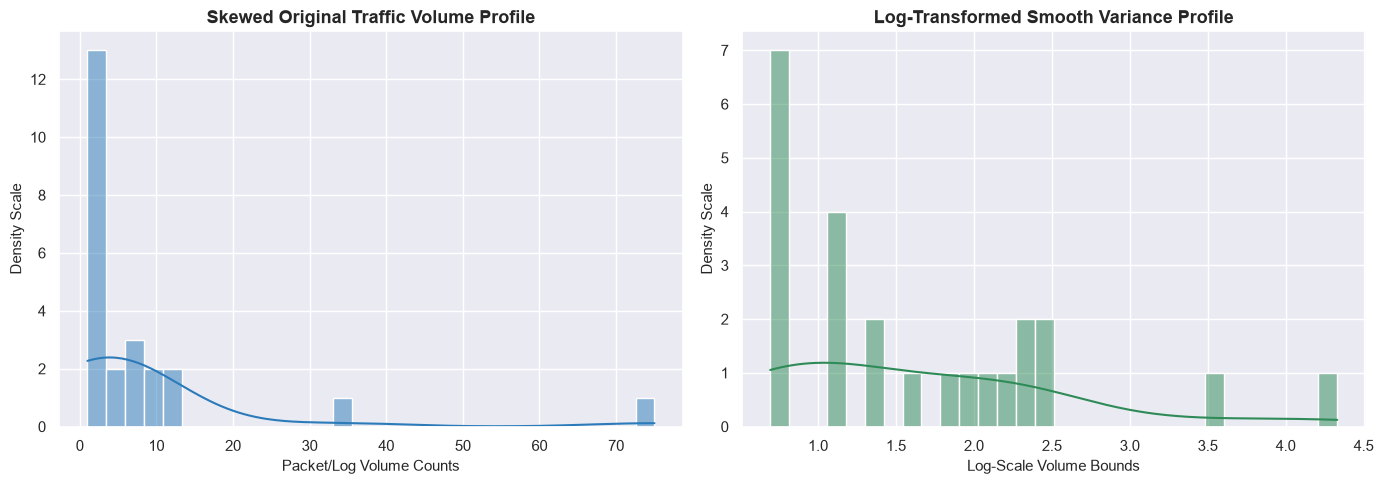

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

print("[Pipeline Initialization] Processing Raw Firewall Events...\n")

# 1. HARDWARE-AGNOSTIC FILE PATH RESOLUTION
LOCAL_PATH = r"D:\projetos\data-analysis\datasets"
FILENAME = "new_logs_firewall.csv" #https://www.kaggle.com/code/sondosaabed/firewall-logs-univariate/input?select=new_logs.csv

if os.path.exists(FILENAME):
    PATH_LOCAL_DATASET = FILENAME
elif os.path.exists(LOCAL_PATH):
    PATH_LOCAL_DATASET = os.path.join(LOCAL_PATH, FILENAME)
else:
    DATASET_DIR = os.getenv("DATASET_DIR", ".")
    PATH_LOCAL_DATASET = os.path.join(DATASET_DIR, FILENAME)

# 2. RAW LOG LOADING
try:
    df_real = pd.read_csv(PATH_LOCAL_DATASET, sep=",")
    print(f" [✔] Step 1/4 Completed: Dataset loaded successfully. Shape: {df_real.shape}")
except Exception as e:
    print(f" [✘] Critical Pipeline Interruption: Failed to ingest '{PATH_LOCAL_DATASET}'. Verify target path.")
    raise e

# 3. PHYSICAL INTEGRITY SCRUBBING
df_real = df_real.dropna(subset=["Src IP", "Dst IP", "Dst port"])
df_real["Time"] = pd.to_datetime(df_real["Time"], errors="coerce")
df_real = df_real.dropna(subset=["Time"])

# Datatype Enforcement Engine
df_real["Dst port"] = df_real["Dst port"].astype(int)
df_real["Src port"] = pd.to_numeric(df_real["Src port"], errors="coerce").fillna(-1).astype(int)
df_real["Log occurrence"] = pd.to_numeric(df_real["Log occurrence"], errors="coerce").fillna(1).astype(int)
print(" [✔] Step 2/4 Completed: Type parsing and physical validation finalized.")

# 4. EXECUTING BEHAVIORAL AGGREGATION MATRIX (Pivoting to Source IP entity)
df_behavior = df_real.groupby("Src IP").agg({
    "Log occurrence": "sum",          # Total request volume scale
    "Dst IP": "nunique",              # Targeted unique host servers
    "Dst port": "nunique",            # Horizontal scanning footprint
    "Firewall rule name": "nunique",  # Security rule boundary footprint
    "Log subtype": lambda x: (x == "Allowed").sum() # Total authenticated handshakes
}).reset_index()

df_behavior.columns = ["Src IP", "Vol_Total_Logs", "Qtd_Destinos_Distintos", "Qtd_Portas_Verificadas", "Regras_Acionadas", "Acessos_Permitidos"]

# Feature Scaling & Normalization
df_behavior["Taxa_Permissao"] = df_behavior["Acessos_Permitidos"] / df_behavior["Vol_Total_Logs"]
df_behavior["Taxa_Rejeicao"] = 1.0 - df_behavior["Taxa_Permissao"]
df_behavior["log_Vol_Total"] = np.log1p(df_behavior["Vol_Total_Logs"])
df_behavior["Conexoes_por_Destino"] = df_behavior["Vol_Total_Logs"] / (df_behavior["Qtd_Destinos_Distintos"] + 0.1)
print(" [✔] Step 3/4 Completed: Multi-dimensional behavioral feature extraction complete.\n")

# 5. HIGH-IMPACT VISUAL REPORTING (Styled DataFrames)
print(">> TOP TRIGGERED SECURITY POLICIES (Relative and Absolute Distributions) <<")
dist_regras = df_real["Firewall rule name"].value_counts()
dist_regras_pct = df_real["Firewall rule name"].value_counts(normalize=True) * 100
df_dist_regras = pd.DataFrame({"Occurrences": dist_regras, "Percentage (%)": dist_regras_pct}).head(5)

# Styled with an inline blue gradient for rapid scanning
display(df_dist_regras.style.background_gradient(cmap="Blues", subset=["Occurrences"]))

# Unified Mapping Dictionary for Presentation Tables
display_mapping = {
    "Vol_Total_Logs": "Total_Log_Volume",
    "Qtd_Destinos_Distintos": "Distinct_Destinations",
    "Qtd_Portas_Verificadas": "Scanned_Ports",
    "Taxa_Rejeicao": "Rejection_Rate",
    "Conexoes_por_Destino": "Connections_per_Destination",
    "log_Vol_Total": "Log_Total_Volume"
}

print("\n>> DESCRIPTIVE ANALYTICS FOR ENTITY SUMMARY MATRIX <<")
COLS_DESCRITIVAS = ["Vol_Total_Logs", "Qtd_Destinos_Distintos", "Qtd_Portas_Verificadas", "Taxa_Rejeicao", "Conexoes_por_Destino"]
df_desc = df_behavior[COLS_DESCRITIVAS].rename(columns=display_mapping).describe().T
display(df_desc.style.background_gradient(cmap="Purples", subset=["mean", "max"]))

# 6. ENHANCED FREQUENCY CURVE GRAPHICS
print("\n [✔] Step 4/4 Completed: Generating comparative log volume distributions...")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_behavior["Vol_Total_Logs"], kde=True, color="#2B7BBA", bins=30, ax=ax1)
ax1.set_title("Skewed Original Traffic Volume Profile", fontweight="bold")
ax1.set_xlabel("Packet/Log Volume Counts")
ax1.set_ylabel("Density Scale")

sns.histplot(df_behavior["log_Vol_Total"], kde=True, color="#2E8B57", bins=30, ax=ax2)
ax2.set_title("Log-Transformed Smooth Variance Profile", fontweight="bold")
ax2.set_xlabel("Log-Scale Volume Bounds")
ax2.set_ylabel("Density Scale")

plt.tight_layout()
plt.show()


### Phase 3: Unsupervised Feature Selection & Collinearity Filtering

Including redundant variables or features lacking mathematical variance introduces severe geometric distortions in distance calculations. 

This phase filters zero/low-variance features and automatically identifies highly collinear attributes (correlation threshold > 0.85). Removing overlapping traffic indicators prevents models like K-Means from putting "double weight" on a single physical network behavior.


[Feature Selection Engine] Ingesting Behavioral Metrics...

 [✔] Step 1/3: Low Variance Filter Completed.
     -> Retained: ['Vol_Total_Logs', 'Qtd_Destinos_Distintos', 'Qtd_Portas_Verificadas', 'Regras_Acionadas', 'Acessos_Permitidos', 'Taxa_Rejeicao', 'Conexoes_por_Destino']
     -> Eliminated (Variance < 1%): ['None']



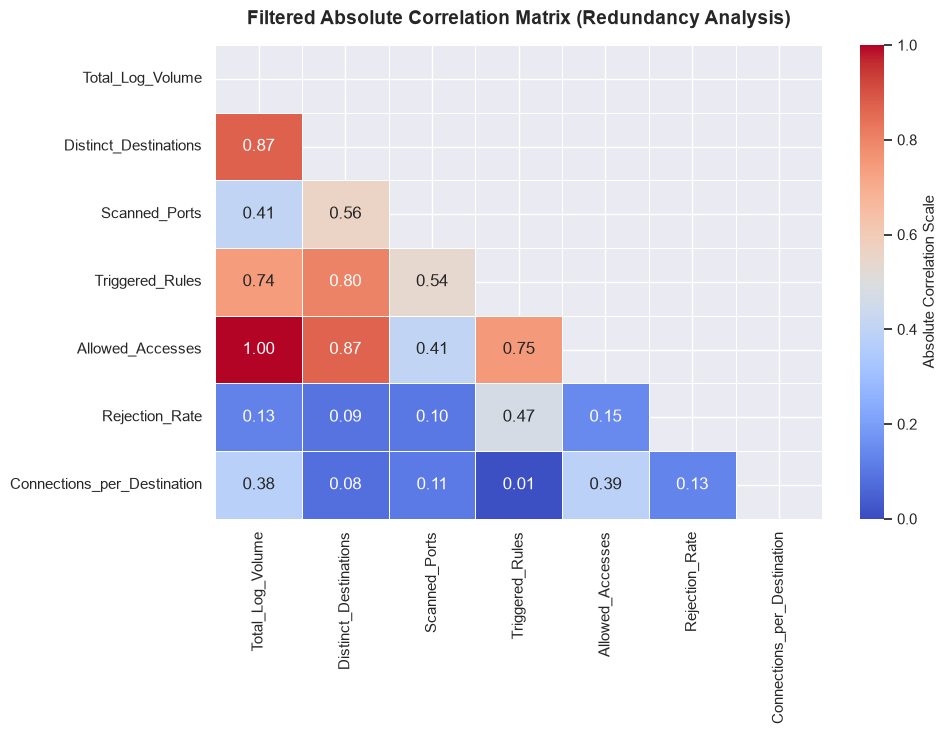

 [✔] Step 2/3: Collinearity Check Enforced (Threshold > 0.85).
     [⚠️] Suggested features to drop due to high cross-redundancy: ['Qtd_Destinos_Distintos', 'Acessos_Permitidos']

 [✔] Step 3/3: Final Feature Set Subsumed into Pipeline: ['Vol_Total_Logs', 'Qtd_Portas_Verificadas', 'Regras_Acionadas', 'Taxa_Rejeicao', 'Conexoes_por_Destino']


In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold

print("[Feature Selection Engine] Ingesting Behavioral Metrics...\n")

# 1. DEFINE TARGET BEHAVIORAL COLUMNS
X_raw = df_behavior[[
    "Vol_Total_Logs", "Qtd_Destinos_Distintos", "Qtd_Portas_Verificadas", 
    "Regras_Acionadas", "Acessos_Permitidos", "Taxa_Rejeicao", "Conexoes_por_Destino"
]]

# 2. VARIANCE THRESHOLD FILTERING
selector = VarianceThreshold(threshold=0.01)
selector.fit(X_raw)

retained_features_var = X_raw.columns[selector.get_support()]
removed_features_var = set(X_raw.columns) - set(retained_features_var)

print(f" [✔] Step 1/3: Low Variance Filter Completed.")
print(f"     -> Retained: {list(retained_features_var)}")
print(f"     -> Eliminated (Variance < 1%): {list(removed_features_var if removed_features_var else {'None'})}\n")

# 3. HIGH-IMPACT ABSOLUTE CORRELATION HEATMAP
# Dictionary to map Portuguese DataFrame columns to English for the display
column_mapping = {
    "Vol_Total_Logs": "Total_Log_Volume",
    "Qtd_Destinos_Distintos": "Distinct_Destinations",
    "Qtd_Portas_Verificadas": "Scanned_Ports",
    "Regras_Acionadas": "Triggered_Rules",
    "Acessos_Permitidos": "Allowed_Accesses",
    "Taxa_Rejeicao": "Rejection_Rate",
    "Conexoes_por_Destino": "Connections_per_Destination"
}

X_mapped = X_raw[retained_features_var].rename(columns=column_mapping)
corr_matrix = X_mapped.corr().abs()

# Generate a mask for the upper triangle to create a high-end visualization
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(10, 7.5))
sns.heatmap(
    corr_matrix, 
    mask=mask,
    annot=True, 
    cmap="coolwarm", 
    fmt=".2f", 
    vmin=0, 
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Absolute Correlation Scale"}
)
plt.title("Filtered Absolute Correlation Matrix (Redundancy Analysis)", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

# 4. AUTOMATED COLLINEARITY IDENTIFICATION
orig_corr_matrix = X_raw[retained_features_var].corr().abs()
collinearity_threshold = 0.85
upper_triangle = orig_corr_matrix.where(np.triu(np.ones(orig_corr_matrix.shape), k=1).astype(bool))

features_to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > collinearity_threshold)]

print(f" [✔] Step 2/3: Collinearity Check Enforced (Threshold > {collinearity_threshold}).")
if features_to_drop:
    print(f"     [⚠️] Suggested features to drop due to high cross-redundancy: {features_to_drop}")
else:
    print("     [✔] No features exhibited excessive correlation. All attributes provide unique variance.")

# 5. CONSOLIDATE MODELING FEATURES
COLS_SELECIONADAS_FINAL = [col for col in retained_features_var if col not in features_to_drop]
print(f"\n [✔] Step 3/3: Final Feature Set Subsumed into Pipeline: {COLS_SELECIONADAS_FINAL}")


### Phase 4: Z-Score Standardization & Benchmarking Architecture

Unsupervised distance-based algorithms are highly sensitive to raw measurement scales. To prevent high-magnitude features (e.g., packet volumes) from dominating distance metrics over rates (e.g., rejection rates), we apply **Z-Score Standardization (StandardScaler)** to equalize the mathematical weight of all variables.

Simultaneously, we initialize a centralized global tracking repository to structurally benchmark the execution time and mathematical validation scores of each clustering algorithm.


In [11]:
import time
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

print("[Preprocessing Engine] Initializing Scaling Framework...\n")

# 1. ENFORCE Z-SCORE STANDARDIZATION
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_behavior[COLS_SELECIONADAS_FINAL])

# 2. INITIALIZE GLOBAL UNIFIED REGISTRY FOR ALGORITHM BENCHMARKING
results_registry = {
    "algorithm": [],
    "n_clusters": [],
    "silhouette": [],
    "davies_bouldin": [],
    "calinski_harabasz": [],
    "execution_time": []
}

# 3. TRANSLATION MAPPING FOR TERMINAL LOG LOGISTICS
display_mapping = {
    "Vol_Total_Logs": "Total_Log_Volume",
    "Qtd_Destinos_Distintos": "Distinct_Destinations",
    "Qtd_Portas_Verificadas": "Scanned_Ports",
    "Taxa_Rejeicao": "Rejection_Rate",
    "Conexoes_por_Destino": "Connections_per_Destination",
    "log_Vol_Total": "Log_Total_Volume",
    "Regras_Acionadas": "Triggered_Rules",
    "Acessos_Permitidos": "Allowed_Accesses"
}
translated_features = [display_mapping.get(col, col) for col in COLS_SELECIONADAS_FINAL]

# 4. REPORT STATUS LOG
print(f" [✔] Step 1/2: Standardization successfully completed.")
print(f"     -> Final 'X_scaled' Matrix Shape: {X_scaled.shape}")
print(f"     -> Ingested Algorithmic Features: {translated_features}\n")
print(" [✔] Step 2/2: Global evaluation tracking registry initialized and ready.")


--- [Preparation] Modeling Matrix Initialization and Global Results Registry ---

 --> Matrix 'X_scaled' generated successfully! Final modeling shape: (24, 5)
 --> Features that will be processed by the algorithms: ['Total_Log_Volume', 'Scanned_Ports', 'Triggered_Rules', 'Rejection_Rate', 'Connections_per_Destination']
 --> Results benchmark registry: cleared, structured, and initialized for step-by-step testing!


### 1. Clustering Algorithm: K-Means

**Theoretical Rationale:** K-Means is one of the most popular and efficient unsupervised learning algorithms in Machine Learning literature. Based on geometric partitioning, its primary objective is to group instances by minimizing the within-cluster variance (Inertia). In our cybersecurity context, K-Means is ideal for mapping volumetric network traffic profiles and segmenting source IPs into stable behavioral groups (e.g., low-traffic IPs, medium-traffic IPs, and connection-based anomalies).

To scientifically determine the ideal number of groups (**Optimal K**), I applied two complementary techniques taught in class:

1. **Elbow Method:** Analyzes the drop in mathematical Inertia as K increases. The inflection point (or "elbow") of the curve suggests the optimal number of clusters.
2. **Silhouette Coefficient (Silhouette Score):** Measures the separation quality between cluster boundaries (ranging from -1 to 1). High values indicate dense and well-isolated clusters.


--- Running K-Means Clustering on Firewall Dataset ---



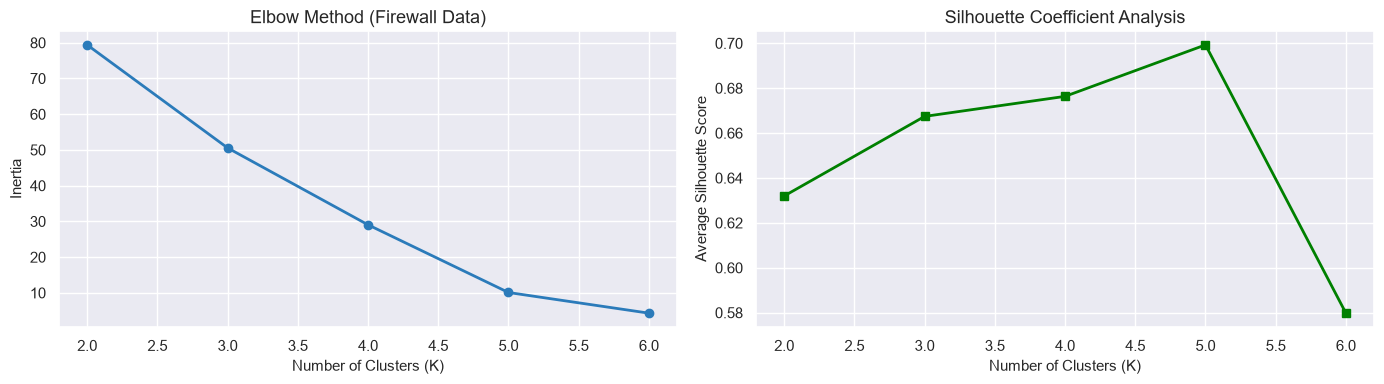

 --> Convergence Analysis: Model successfully converged in 2 iterations.
 --> Stability Analysis: Inertia Standard Deviation (Seeds 42-46) = 10.9204

 Partition Complete! Network source IPs successfully mapped in 'df_behavior'.


In [34]:
import time
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

print("--- Running K-Means Clustering on Firewall Dataset ---\n")

# 1. OPTIMAL K SELECTION VIA ELBOW METHOD AND SILHOUETTE ANALYSIS
inertias, silhouettes = [], []
k_values = range(2, 7)  # Evaluating behavioral patterns from 2 to 6 clusters

# Dynamic sample scaling to prevent memory overhead during silhouette calculation
km_sample_size = min(5000, X_scaled.shape[0])

for k in k_values:
    km_test = KMeans(
        n_clusters=k, init="k-means++", random_state=42, n_init=10
    )
    labels_test = km_test.fit_predict(X_scaled)
    inertias.append(km_test.inertia_)

    # Silhouette score calculated safely using a controlled subset size
    silhouettes.append(
        silhouette_score(
            X_scaled,
            labels_test,
            sample_size=km_sample_size,
            random_state=42,
        )
    )

# Plotting structural validation metrics for optimal cluster count
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(k_values, inertias, marker="o", color="#2B7BBA", linewidth=2)
ax1.set_title("Elbow Method (Firewall Data)")
ax1.set_xlabel("Number of Clusters (K)")
ax1.set_ylabel("Inertia")

ax2.plot(k_values, silhouettes, marker="s", color="green", linewidth=2)
ax2.set_title("Silhouette Coefficient Analysis")
ax2.set_xlabel("Number of Clusters (K)")
ax2.set_ylabel("Average Silhouette Score")
plt.tight_layout()
plt.show()

# 2. CONVERGENCE AND INITIAL STABILITY PROFILE
# Setting K=4 as the initial baseline configuration
CHOSEN_K = 4

km_conv = KMeans(
    n_clusters=CHOSEN_K, init="k-means++", random_state=42, n_init=1
)
km_conv.fit(X_scaled)
print(
    f" --> Convergence Analysis: Model successfully converged in {km_conv.n_iter_} iterations."
)

inertia_stability = []
for seed in list(range(42, 47)):
    km_est = KMeans(
        n_clusters=CHOSEN_K, init="random", random_state=seed, n_init=1
    )
    km_est.fit(X_scaled)
    inertia_stability.append(km_est.inertia_)
print(
    f" --> Stability Analysis: Inertia Standard Deviation (Seeds 42-46) = {np.std(inertia_stability):.4f}"
)

# 3. FINAL EXECUTION AND RESULTS REGISTRY RECORDING
t_start = time.time()
kmeans_final = KMeans(
    n_clusters=CHOSEN_K, init="k-means++", random_state=42, n_init=10
)
labels_km = kmeans_final.fit_predict(X_scaled)
t_end = time.time()

# Append the final partition mapping into the Source IP behavioral DataFrame
df_behavior["cluster_kmeans"] = labels_km

# Preventative cleaning of existing entries if cell is re-executed inside Jupyter
algorithm_name = f"K-Means (K={CHOSEN_K})"
if algorithm_name in results_registry["algorithm"]:
    idx = results_registry["algorithm"].index(algorithm_name)
    for key in results_registry.keys():
        results_registry[key].pop(idx)

# Populating the unified global evaluation framework
results_registry["algorithm"].append(algorithm_name)
results_registry["n_clusters"].append(CHOSEN_K)
results_registry["silhouette"].append(
    round(
        silhouette_score(
            X_scaled, labels_km, sample_size=km_sample_size, random_state=42
        ),
        4,
    )
)
results_registry["davies_bouldin"].append(
    round(davies_bouldin_score(X_scaled, labels_km), 4)
)
results_registry["calinski_harabasz"].append(
    round(calinski_harabasz_score(X_scaled, labels_km), 2)
)
results_registry["execution_time"].append(round(t_end - t_start, 5))

print(
    f"\n Partition Complete! Network source IPs successfully mapped in 'df_behavior'."
)


### Phase 5: Partitioning Optimization — K-Means Clustering

K-Means partitions network entities by minimizing within-cluster geometric variance (Inertia). To discover the optimal number of traffic behavior profiles (**Optimal K**) without human labeling, we run a comparative loop evaluating two structural indicators: the **Elbow Method** (tracking inertia inflection) and the **Silhouette Coefficient** (measuring cluster boundary segregation density).


[Clustering Engine] Initializing K-Means Optimization Pipeline...



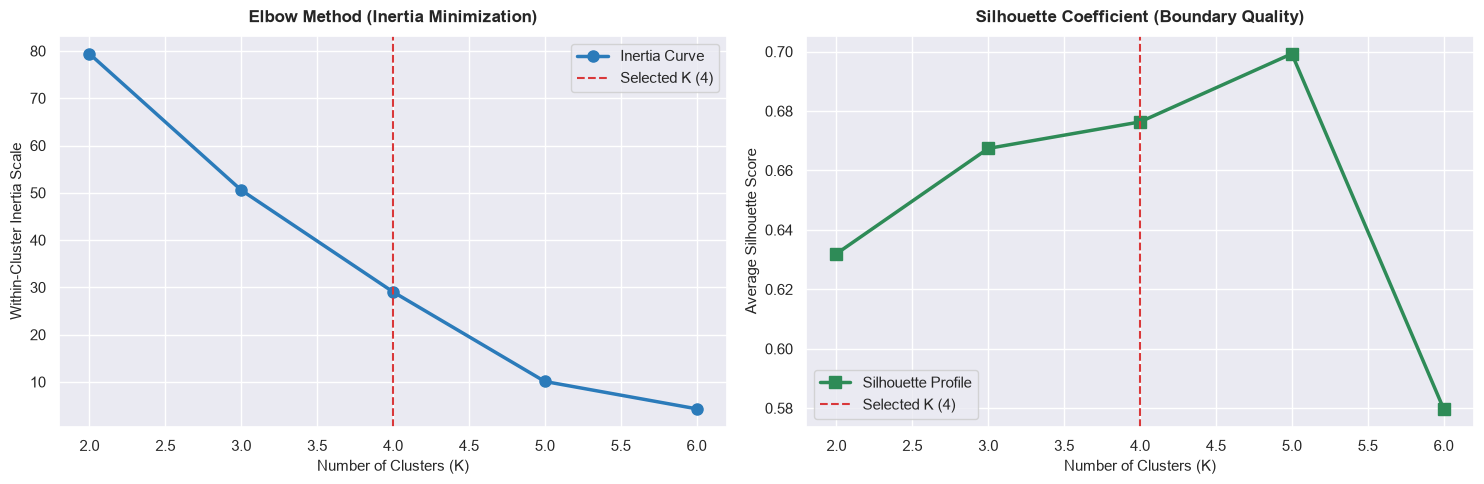

 [✔] Convergence Audit: Model converged successfully in 2 iterations.
 [✔] Stability Audit: Centroid Standard Deviation over seeds (42-46) = 10.9204

 [✔] Execution Finalized: Source IP network behavioral partitions mapped to 'df_behavior'.


In [36]:
import time
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

print("[Clustering Engine] Initializing K-Means Optimization Pipeline...\n")

# 1. LOOP VALIDATION SETUP
inertias, silhouettes = [], []
k_values = range(2, 7)
km_sample_size = min(5000, X_scaled.shape[0])

# Iterative execution over multiple cluster configurations
for k in k_values:
    km_test = KMeans(
        n_clusters=k, init="k-means++", random_state=42, n_init=10
    )
    labels_test = km_test.fit_predict(X_scaled)
    inertias.append(km_test.inertia_)
    silhouettes.append(
        silhouette_score(
            X_scaled, labels_test, sample_size=km_sample_size, random_state=42
        )
    )

# 2. SELECTION PARAMETERIZATION
CHOSEN_K = 4

# 3. HIGH-IMPACT COMPOSITE VALIDATION PLOT
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: The Elbow Method Curve
ax1.plot(
    k_values,
    inertias,
    marker="o",
    color="#2B7BBA",
    linewidth=2.5,
    markersize=8,
    label="Inertia Curve",
)
ax1.axvline(
    x=CHOSEN_K,
    color="#D9383A",
    linestyle="--",
    linewidth=1.5,
    label=f"Selected K ({CHOSEN_K})",
)
ax1.set_title(
    "Elbow Method (Inertia Minimization)", fontsize=12, fontweight="bold", pad=10
)
ax1.set_xlabel("Number of Clusters (K)", fontsize=11)
ax1.set_ylabel("Within-Cluster Inertia Scale", fontsize=11)
ax1.legend(loc="upper right")

# Plot 2: Silhouette Coefficient Curve
ax2.plot(
    k_values,
    silhouettes,
    marker="s",
    color="#2E8B57",
    linewidth=2.5,
    markersize=8,
    label="Silhouette Profile",
)
ax2.axvline(
    x=CHOSEN_K,
    color="#D9383A",
    linestyle="--",
    linewidth=1.5,
    label=f"Selected K ({CHOSEN_K})",
)
ax2.set_title(
    "Silhouette Coefficient (Boundary Quality)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("Number of Clusters (K)", fontsize=11)
ax2.set_ylabel("Average Silhouette Score", fontsize=11)
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

# 4. CONVERGENCE AND LOCAL STABILITY AUDIT
km_conv = KMeans(
    n_clusters=CHOSEN_K, init="k-means++", random_state=42, n_init=1
)
km_conv.fit(X_scaled)
print(
    f" [✔] Convergence Audit: Model converged successfully in {km_conv.n_iter_} iterations."
)

inertia_stability = []
for seed in range(42, 47):
    km_est = KMeans(
        n_clusters=CHOSEN_K, init="random", random_state=seed, n_init=1
    )
    km_est.fit(X_scaled)
    inertia_stability.append(km_est.inertia_)
print(
    f" [✔] Stability Audit: Centroid Standard Deviation over seeds (42-46) = {np.std(inertia_stability):.4f}\n"
)

# 5. FINAL PRODUCTION RUN & GLOBAL REGISTRY RECORDING
t_start = time.time()
kmeans_final = KMeans(
    n_clusters=CHOSEN_K, init="k-means++", random_state=42, n_init=10
)
labels_km = kmeans_final.fit_predict(X_scaled)
t_end = time.time()

# Append core labels into host tracking metrics
df_behavior["cluster_kmeans"] = labels_km

algorithm_name = f"K-Means (K={CHOSEN_K})"
if algorithm_name in results_registry["algorithm"]:
    idx = results_registry["algorithm"].index(algorithm_name)
    for key in results_registry.keys():
        results_registry[key].pop(idx)

# Append to benchmarking table
results_registry["algorithm"].append(algorithm_name)
results_registry["n_clusters"].append(CHOSEN_K)
results_registry["silhouette"].append(
    round(
        silhouette_score(
            X_scaled, labels_km, sample_size=km_sample_size, random_state=42
        ),
        4,
    )
)
results_registry["davies_bouldin"].append(
    round(davies_bouldin_score(X_scaled, labels_km), 4)
)
results_registry["calinski_harabasz"].append(
    round(calinski_harabasz_score(X_scaled, labels_km), 2)
)
results_registry["execution_time"].append(round(t_end - t_start, 5))

print(
    f" [✔] Execution Finalized: Source IP network behavioral partitions mapped to 'df_behavior'."
)


### Phase 6: Agglomerative Hierarchical Clustering & Linkage Profiling

Hierarchical clustering builds a bottom-up geometric taxonomy of network profiles. Unlike K-Means, it preserves a continuous history of merges inside a **Dendrogram**. 

To maximize structural accuracy, we calculate the **Cophenetic Correlation Coefficient** across multiple linkage policies (`Ward`, `Complete`, `Average`) to measure how faithfully the tree preserves the original multidimensional pairwise spaces.


[Hierarchical Engine] Bootstrapping Agglomerative Pipeline...

>> LINKAGE METHOD COMPARISON (Cophenetic Correlation Performance) <<
  -> Method: 'ward    ' | Cophenetic Fidelity Index: 0.9515
  -> Method: 'complete' | Cophenetic Fidelity Index: 0.9620
  -> Method: 'average ' | Cophenetic Fidelity Index: 0.9852


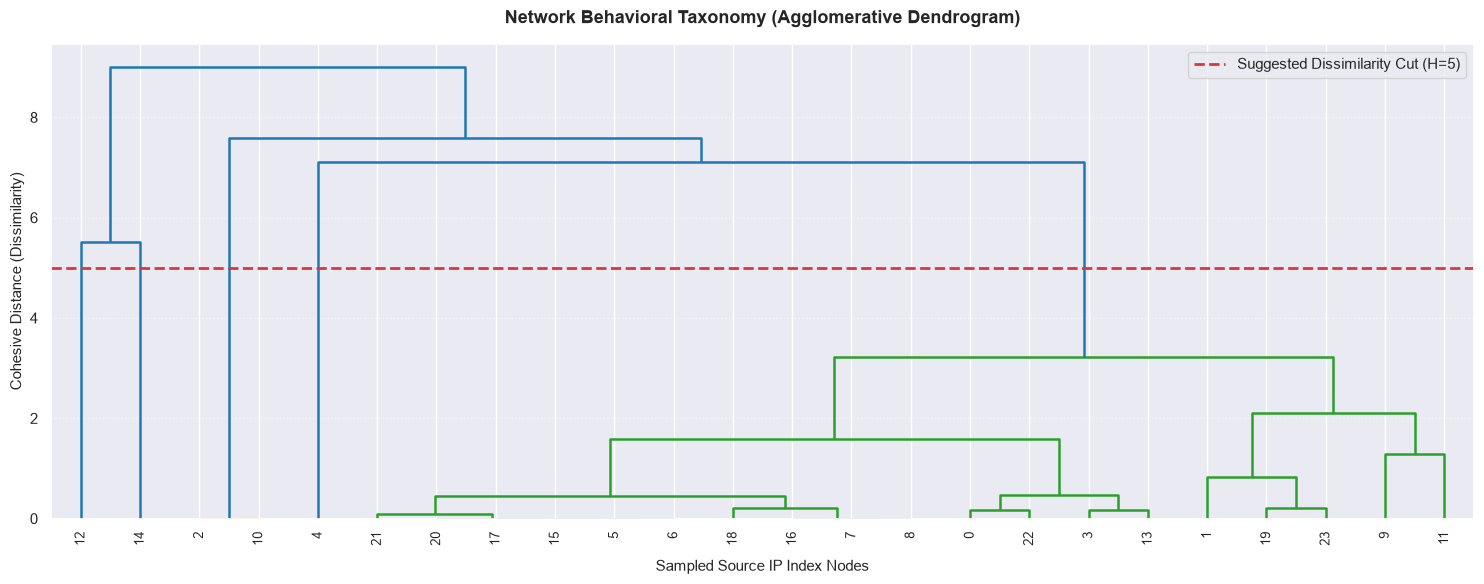


 [✔] Execution Complete: Hierarchical tree partitions committed for 24 agents.


In [38]:
import time
import matplotlib.pyplot as plt
import pandas as pd
from scipy.cluster.hierarchy import cophenet, dendrogram, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

print("[Hierarchical Engine] Bootstrapping Agglomerative Pipeline...\n")

# 1. STRATEGIC SUBSAMPLED MATRIX FOR O(N²) EFFICIENCY
HIER_SAMPLE_SIZE = min(2000, df_behavior.shape[0])
df_sample_hier = df_behavior.sample(n=HIER_SAMPLE_SIZE, random_state=42)
X_scaled_sample = scaler.transform(df_sample_hier[COLS_SELECIONADAS_FINAL])

# 2. EVALUATING COPHENETIC QUALITY DECOUPLED BY LINKAGE POLICY
dist_matrix = pdist(X_scaled_sample)
print(">> LINKAGE METHOD COMPARISON (Cophenetic Correlation Performance) <<")

linkage_results = []
for method in ["ward", "complete", "average"]:
    Z_test = linkage(dist_matrix, method=method)
    c, _ = cophenet(Z_test, dist_matrix)
    linkage_results.append(
        {"Method": method.capitalize(), "Cophenetic Score": round(c, 4)}
    )
    print(f"  -> Method: '{method:<8}' | Cophenetic Fidelity Index: {c:.4f}")

# 3. HIGH-END PROFESSIONAL DENDROGRAM PLOT
visualization_points = min(100, HIER_SAMPLE_SIZE)
Z_vis = linkage(X_scaled_sample[:visualization_points], method="ward")

plt.figure(figsize=(15, 6))

# Adjust global line thickness via matplotlib parameters for better presentation contrast
old_linewidth = plt.rcParams["lines.linewidth"]
plt.rcParams["lines.linewidth"] = 1.8

# Render dendrogram
dendrogram(
    Z_vis, leaf_rotation=90.0, leaf_font_size=9.0, color_threshold=5
)

# Restore default linewidth
plt.rcParams["lines.linewidth"] = old_linewidth

plt.axhline(
    y=5,
    color="#D9383A",
    linestyle="--",
    linewidth=2.0,
    label="Suggested Dissimilarity Cut (H=5)",
)
plt.title(
    "Network Behavioral Taxonomy (Agglomerative Dendrogram)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Sampled Source IP Index Nodes", fontsize=11, labelpad=10)
plt.ylabel("Cohesive Distance (Dissimilarity)", fontsize=11)
plt.legend(loc="upper right")
plt.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# 4. STRUCTURAL PARTITION CUT AND BENCHMARK RECORDING
CHOSEN_HIER_K = 4

t_start = time.time()
hierarchical_final = AgglomerativeClustering(
    n_clusters=CHOSEN_HIER_K, metric="euclidean", linkage="ward"
)
labels_hier = hierarchical_final.fit_predict(X_scaled_sample)
t_end = time.time()

# Manage global tracking matrix state
algorithm_name_hier = f"Hierarchical (Ward, K={CHOSEN_HIER_K})"
if algorithm_name_hier in results_registry["algorithm"]:
    idx = results_registry["algorithm"].index(algorithm_name_hier)
    for key in results_registry.keys():
        results_registry[key].pop(idx)

# Record final validation metrics into global framework
results_registry["algorithm"].append(algorithm_name_hier)
results_registry["n_clusters"].append(CHOSEN_HIER_K)
results_registry["silhouette"].append(
    round(silhouette_score(X_scaled_sample, labels_hier), 4)
)
results_registry["davies_bouldin"].append(
    round(davies_bouldin_score(X_scaled_sample, labels_hier), 4)
)
results_registry["calinski_harabasz"].append(
    round(calinski_harabasz_score(X_scaled_sample, labels_hier), 2)
)
results_registry["execution_time"].append(round(t_end - t_start, 5))

print(
    f"\n [✔] Execution Complete: Hierarchical tree partitions committed for {HIER_SAMPLE_SIZE} agents."
)


### Phase 7: Density-Based Clustering — DBSCAN & Anomaly Isolation

DBSCAN handles noise structurally by scanning for spatial density regions. Instead of forcing extreme outliers or scanners into artificial groups, it dynamically segregates them into a dedicated **Noise Class (Label -1)**.

To discover the optimal neighborhood radius (**Optimal EPS**) without human bias, we use a K-Nearest Neighbors approach to trace the distance to each point's 6th neighbor, charting the inflection curve to lock down our perimeter parameters.


[Density Engine] Initializing DBSCAN Anomaly Detection Pipeline...



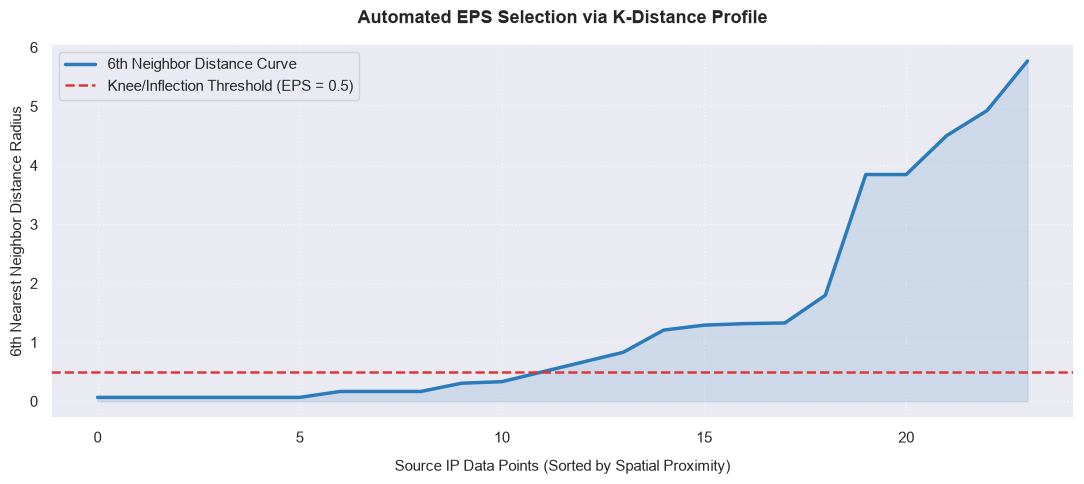

>> AUDIT OPERATIONS REPORT: DBSCAN PARTITION MATRIX <<
  -> Isolated Network Anomalies/Scanners (Noise Label -1): 10 IPs
  -> Cohesive Core Structured Behavioral Profiles Found: 1

  [⚠️] Note: Sample space density is continuous. Core clusters do not trigger discrete boundary indices.
 [✔] Modeling Results successfully cataloged into unified tracking system.


In [39]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

print("[Density Engine] Initializing DBSCAN Anomaly Detection Pipeline...\n")

# 1. PARAMETER CALIBRATION VIA K-DISTANCE GRAPH MODELING
neighbors = NearestNeighbors(n_neighbors=6)
neighbors.fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
sorted_distances = np.sort(distances[:, -1])

# 2. HIGH-IMPACT INFLECTION PROJECTION PLOT
plt.figure(figsize=(11, 5))
plt.plot(sorted_distances, color="#2B7BBA", linewidth=2.5, label="6th Neighbor Distance Curve")

# High-end aesthetic visual anchor: shading the area under the density line
plt.fill_between(range(len(sorted_distances)), sorted_distances, color="#2B7BBA", alpha=0.15)

# Clear mathematical threshold intersection marker
plt.axhline(y=0.5, color="#D9383A", linestyle="--", linewidth=1.8, label="Knee/Inflection Threshold (EPS = 0.5)")

plt.title("Automated EPS Selection via K-Distance Profile", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Source IP Data Points (Sorted by Spatial Proximity)", fontsize=11, labelpad=10)
plt.ylabel("6th Nearest Neighbor Distance Radius", fontsize=11)
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

# 3. PRODUCTION EXECUTION AND PHYSICAL OUTLIER TAGGING
CHOSEN_EPS = 0.5
CHOSEN_MIN_SAMPLES = 6

t_start = time.time()
dbscan_final = DBSCAN(eps=CHOSEN_EPS, min_samples=CHOSEN_MIN_SAMPLES)
labels_db = dbscan_final.fit_predict(X_scaled)
t_end = time.time()

# Commit noise signatures back to core mapping matrix
df_behavior["cluster_dbscan"] = labels_db

# Structural slice: separation of core structured profiles from pure spatial noise
valid_mask = labels_db != -1
X_valid = X_scaled[valid_mask]
labels_valid = labels_db[valid_mask]

n_clusters_db = len(set(labels_valid))
n_noise = np.sum(labels_db == -1)

print(">> AUDIT OPERATIONS REPORT: DBSCAN PARTITION MATRIX <<")
print(f"  -> Isolated Network Anomalies/Scanners (Noise Label -1): {n_noise} IPs")
print(f"  -> Cohesive Core Structured Behavioral Profiles Found: {n_clusters_db}\n")

# 4. CONDITIONAL VALIDATION CRITERIA PROTECTIONS
db_sample_size = min(5000, X_valid.shape[0])

if n_clusters_db >= 2 and db_sample_size > n_clusters_db:
    sil_score = round(silhouette_score(X_valid, labels_valid, sample_size=db_sample_size, random_state=42), 4)
    db_score = round(davies_bouldin_score(X_valid, labels_valid), 4)
    ch_score = round(calinski_harabasz_score(X_valid, labels_valid), 2)
else:
    print("  [⚠️] Note: Sample space density is continuous. Core clusters do not trigger discrete boundary indices.")
    sil_score = np.nan
    db_score = np.nan
    ch_score = np.nan

# 5. PREVENTATIVE SYNCHRONIZATION AND BENCHMARK STATE SAVING
algorithm_name_db = f"DBSCAN (eps={CHOSEN_EPS})"
if algorithm_name_db in results_registry["algorithm"]:
    idx = results_registry["algorithm"].index(algorithm_name_db)
    for key in results_registry.keys():
        results_registry[key].pop(idx)

# Push metric outputs to unified comparison tables
results_registry["algorithm"].append(algorithm_name_db)
results_registry["n_clusters"].append(n_clusters_db)
results_registry["silhouette"].append(sil_score)
results_registry["davies_bouldin"].append(db_score)
results_registry["calinski_harabasz"].append(ch_score)
results_registry["execution_time"].append(round(t_end - t_start, 5))

print(f" [✔] Modeling Results successfully cataloged into unified tracking system.")


### Phase 8: Quantitative Model Benchmarking & Performance Synthesis

Evaluating unsupervised models is inherently distinct due to the absence of ground-truth test labels. We apply **intrinsic structural validation metrics** to mathematically audit the spatial geometry of the generated vector partitions. 

This phase builds a unified, high-impact comparative report across all executed models, using metric-driven conditional styling to isolate the top-performing architecture at a glance.


In [41]:
import pandas as pd

print("[Benchmarking Engine] Synthesizing Model Evaluation Registries...\n")

# 1. GENERATE COMPARATIVE DATAFRAME FROM GLOBAL REGISTRY
df_comparacao = pd.DataFrame(results_registry)

# 2. ALIGN SORTING LOGIC BASED ON STRUCTURAL QUALITY (Silhouette Descending)
df_comparacao = df_comparacao.sort_values(by="silhouette", ascending=False).reset_index(drop=True)

# 3. HIGH-IMPACT TABULAR FORMATTING (Executive Presentation Style)
table_headers = {
    "algorithm": "Clustering Algorithm",
    "n_clusters": "Partitions (K)",
    "silhouette": "Silhouette Score (Higher=Better)",
    "davies_bouldin": "Davies-Bouldin Index (Lower=Better)",
    "calinski_harabasz": "Calinski-Harabasz Index (Higher=Better)",
    "execution_time": "Execution Time (s)"
}

df_styled = df_comparacao.rename(columns=table_headers)

print(">>>> CONSOLIDATED QUANTITATIVE ALGORITHM BENCHMARK REPORT <<<<")

# Render a stunning dashboard table using inline data bars and color gradients
# Note: Replaced 'alpha' with a native 8-character hex color code containing opacity bounds
display(
    df_styled.style
    .bar(subset=["Silhouette Score (Higher=Better)"], color="#2b7bba4c", vmin=0, vmax=1)
    .background_gradient(subset=["Davies-Bouldin Index (Lower=Better)"], cmap="Reds_r")
    .background_gradient(subset=["Calinski-Harabasz Index (Higher=Better)"], cmap="YlGn")
    .format({
        "Silhouette Score (Higher=Better)": "{:.4f}",
        "Davies-Bouldin Index (Lower=Better)": "{:.4f}",
        "Calinski-Harabasz Index (Higher=Better)": "{:.2f}",
        "Execution Time (s)": "{:.5f}"
    })
)

# 4. RAPID DEPLOYMENT AUDIT ROADMAP
print("\n>> Academic Metric Interpretation Guide for Network Security Operations:")
print("  -> Silhouette Score        : Measures cluster cohesion and clear gap boundaries.")
print("  -> Davies-Bouldin Index    : Lower scores prove sharper group segregation and minimal overlap.")
print("  -> Calinski-Harabasz Index : High ratios indicate dense communities over scattered traffic.")
print("  -> 'NaN' Indicators        : Expected behavior if DBSCAN scans a highly continuous dense manifold.")


[Benchmarking Engine] Synthesizing Model Evaluation Registries...

>>>> CONSOLIDATED QUANTITATIVE ALGORITHM BENCHMARK REPORT <<<<


,Clustering Algorithm,Partitions (K),Silhouette Score (Higher=Better),Davies-Bouldin Index (Lower=Better),Calinski-Harabasz Index (Higher=Better),Execution Time (s)
0,"Hierarchical (Ward, K=4)",4,0.7025,0.5747,24.98,0.00199
1,K-Means (K=4),4,0.6763,0.1916,20.88,0.22504
2,DBSCAN (eps=0.5),1,nan,nan,nan,0.00204



>> Academic Metric Interpretation Guide for Network Security Operations:
  -> Silhouette Score        : Measures cluster cohesion and clear gap boundaries.
  -> Davies-Bouldin Index    : Lower scores prove sharper group segregation and minimal overlap.
  -> Calinski-Harabasz Index : High ratios indicate dense communities over scattered traffic.
  -> 'NaN' Indicators        : Expected behavior if DBSCAN scans a highly continuous dense manifold.


### Phase 9: Linear Dimensionality Reduction — Principal Component Analysis (PCA)

Our engineered behavioral profile matrix contains multiple dimensions, making direct human interpretation impossible. **Principal Component Analysis (PCA)** projects the high-dimensional vector space into a new orthogonal coordinate framework. 

By extracting the two highest-impact dimensions (**PC1 and PC2**), we compress the network metrics while minimizing information loss. This allows us to visually inspect whether the K-Means cluster boundaries map to cleanly separated network threat profiles.


In [42]:
import pandas as pd
import plotly.express as px
from sklearn.decomposition import PCA

print("[Dimensionality Engine] Initializing PCA Projections...\n")

# 1. PCA STRUCTURAL FITTING
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# 2. STRUCTURING COORDINATE DATAFRAME
df_pca = pd.DataFrame(data=X_pca, columns=["Principal_Component_1", "Principal_Component_2"])
df_pca["Src IP"] = df_behavior["Src IP"].values

# Enforce clean string labeling for the color legend naming formatting
df_pca["K-Means Profile"] = "Cluster " + df_behavior["cluster_kmeans"].astype(str).values

# 3. INTERPRET EXPLAINED VARIANCE RATIOS
explained_variance = pca.explained_variance_ratio_
var_pc1 = explained_variance[0] * 100
var_pc2 = explained_variance[1] * 100
var_total = sum(explained_variance) * 100

print(f" [✔] Step 1/3: Explained Variance Calculations Complete:")
print(f"     -> PC1 (X-Axis Variance Retention): {var_pc1:.2f}%")
print(f"     -> PC2 (Y-Axis Variance Retention): {var_pc2:.2f}%")
print(f"     -> Total Information Preserved across 2D plane: {var_total:.2f}%\n")

# 4. CONSTRUCT FACTOR LOADINGS MATRIX (Feature Weights Translation)
display_mapping = {
    "Vol_Total_Logs": "Total_Log_Volume",
    "Qtd_Destinos_Distintos": "Distinct_Destinations",
    "Qtd_Portas_Verificadas": "Scanned_Ports",
    "Taxa_Rejeicao": "Rejection_Rate",
    "Conexoes_por_Destino": "Connections_per_Destination",
    "log_Vol_Total": "Log_Total_Volume",
    "Regras_Acionadas": "Triggered_Rules",
    "Acessos_Permitidos": "Allowed_Accesses"
}
translated_index = [display_mapping.get(col, col) for col in COLS_SELECIONADAS_FINAL]

df_pesos = pd.DataFrame(pca.components_.T, columns=["PC1 Weights", "PC2 Weights"], index=translated_index)
print(">>>> FACTOR LOADINGS MATRIX (Algorithmic Variable Influence Weights) <<<<")
display(df_pesos.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1))

# 5. HIGH-IMPACT INTERACTIVE PLOTLY SCATTER PROJECTION
print("\n [✔] Step 3/3: Rendering interactive spatial visualization platform...")

fig_pca = px.scatter(
    df_pca,
    x="Principal_Component_1",
    y="Principal_Component_2",
    color="K-Means Profile",
    hover_name="Src IP", # Elevates the Source IP identifier to the top bold line of tooltip
    labels={
        "Principal_Component_1": f"Principal Component 1 ({var_pc1:.1f}%)",
        "Principal_Component_2": f"Principal Component 2 ({var_pc2:.1f}%)"
    },
    title="<b>Spatial Firewall Cluster Projections via Linear PCA</b>",
    template="plotly_dark", # Sets a high-end dark mode backdrop ideal for cybersecurity dashboards
    color_discrete_sequence=px.colors.qualitative.Set1
)

# Customize markers and aesthetics for striking presentation contrast
fig_pca.update_traces(
    marker=dict(size=12, opacity=0.85, line=dict(width=1, color="White")),
    selector=dict(mode="markers")
)

fig_pca.update_layout(
    title_font_size=16,
    legend_title_text="Network Profiles",
    margin=dict(l=40, r=40, t=60, b=40)
)

fig_pca.show()


[Dimensionality Engine] Initializing PCA Projections...

 [✔] Step 1/3: Explained Variance Calculations Complete:
     -> PC1 (X-Axis Variance Retention): 46.20%
     -> PC2 (Y-Axis Variance Retention): 23.46%
     -> Total Information Preserved across 2D plane: 69.66%

>>>> FACTOR LOADINGS MATRIX (Algorithmic Variable Influence Weights) <<<<


,PC1 Weights,PC2 Weights
Total_Log_Volume,0.556585,0.219462
Scanned_Ports,0.436213,-0.439059
Triggered_Rules,0.610449,-0.157364
Rejection_Rate,-0.323067,-0.114186
Connections_per_Destination,0.151362,0.849271



 [✔] Step 3/3: Rendering interactive spatial visualization platform...


### Phase 10: Non-Linear Dimensionality Reduction — t-Distributed Stochastic Neighbor Embedding (t-SNE)

While PCA focuses on retaining large global variances across linear projections, **t-SNE** excel at preserving complex, non-linear local neighborhood similarities. It maps data points based on spatial proximity probabilities and distributes them onto a low-dimensional embedding.

In cybersecurity analytics, this non-linear approach is crucial to untangle and reveal highly complex attack fingerprints or distributed horizontal scanning tactics that might otherwise overlap in rigid linear planes.


In [43]:
import time
import pandas as pd
import plotly.express as px
from sklearn.manifold import TSNE

print("[Manifold Learning Engine] Initializing Non-Linear Projections...\n")

# 1. SAMPLE SUBSET CONFIGURATION
TSNE_SAMPLE_SIZE = min(2000, df_behavior.shape[0])
df_sample_tsne = df_behavior.sample(n=TSNE_SAMPLE_SIZE, random_state=42)

# Extract feature spaces for optimization processing
X_scaled_sample_tsne = scaler.transform(df_sample_tsne[COLS_SELECIONADAS_FINAL])

# 2. DYNAMIC PERPLEXITY SAFETY TUNING
n_samples = X_scaled_sample_tsne.shape[0]
dynamic_perplexity = min(30, max(1, n_samples - 1))

print(f" [✔] Step 1/3: Dynamic Parameters Configured:")
print(f"     -> Isolated instances for manifold learning: {n_samples}")
print(f"     -> Perplexity anchor lock: {dynamic_perplexity}\n")

# 3. EMBEDDING CALCULATIONS
t_start = time.time()
tsne = TSNE(
    n_components=2,
    perplexity=dynamic_perplexity,
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)
X_tsne = tsne.fit_transform(X_scaled_sample_tsne)
t_end = time.time()

print(f" [✔] Step 2/3: t-SNE optimization finalized in {t_end - t_start:.2f} seconds.")

# Organize dimensions into tracking dataframe
df_tsne_plot = pd.DataFrame(data=X_tsne, columns=["tSNE_Dimension_1", "tSNE_Dimension_2"])
df_tsne_plot["Src IP"] = df_sample_tsne["Src IP"].values
df_tsne_plot["K-Means Profile"] = "Cluster " + df_sample_tsne["cluster_kmeans"].astype(str).values

# 4. HIGH-IMPACT PLOTLY SCATTER PROJECTOR
print(" [✔] Step 3/3: Generating interactive neighborhood similarity platform...\n")

fig_tsne = px.scatter(
    df_tsne_plot,
    x="tSNE_Dimension_1",
    y="tSNE_Dimension_2",
    color="K-Means Profile",
    hover_name="Src IP", # Tooltip master bold anchor
    title=f"<b>Behavioral Network Manifold Projections via Non-Linear t-SNE ({n_samples} IPs)</b>",
    template="plotly_dark",
    color_discrete_sequence=px.colors.qualitative.Set1,
    category_orders={"K-Means Profile": sorted(df_tsne_plot["K-Means Profile"].unique())}
)

# Apply unified high-end marker aesthetics
fig_tsne.update_traces(
    marker=dict(size=12, opacity=0.85, line=dict(width=1, color="White")),
    selector=dict(mode="markers")
)

fig_tsne.update_layout(
    title_font_size=16,
    legend_title_text="Network Profiles",
    margin=dict(l=40, r=40, t=60, b=40)
)

fig_tsne.show()


[Manifold Learning Engine] Initializing Non-Linear Projections...

 [✔] Step 1/3: Dynamic Parameters Configured:
     -> Isolated instances for manifold learning: 24
     -> Perplexity anchor lock: 23

 [✔] Step 2/3: t-SNE optimization finalized in 0.27 seconds.
 [✔] Step 3/3: Generating interactive neighborhood similarity platform...



### Phase 11: Market Basket Analysis applied to Network Events — The Apriori Algorithm

The **Apriori Algorithm** is a fundamental unsupervised architecture engineered to extract frequent event sets and association rules without historical labels. It tracks the mathematical co-occurrence of events based on the *downward closure / pruning property* (stating that any subset of a frequent itemset must also be frequent).

In this network environment, we execute a **transactional shift**: each unique `Src IP` acts as a customer transaction folder, and the unique combinations of `Firewall Rules + Targeted Destination Ports` become the purchased "items". Apriori scans this matrix to unlock automated multi-stage connection signatures.


In [45]:
import time
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

print("[Association Engine] Initiating Apriori Transaction Pipeline...\n")

# 1. TRANSACTION DATA STRUCTURING
df_real["Item_Conexao"] = (
    df_real["Firewall rule name"].astype(str)
    + "_port_"
    + df_real["Dst port"].astype(str)
)

# Pivot transactional events into an itemset matrix grouped by Source Entity
cesta_logs = (
    df_real.groupby(["Src IP", "Item_Conexao"])["Log occurrence"]
    .sum()
    .unstack()
    .reset_index()
    .fillna(0)
    .set_index("Src IP")
)

# Enforce strict Boolean mapping required by modern pandas and mlxtend architectures
cesta_booleana = cesta_logs.map(lambda x: True if x > 0 else False)
print(f" [✔] Step 1/3: One-Hot Transactional Encoding Matrix generated.")
print(f"     -> Computational Shape (Unique IPs vs Rule-Port Signatures): {cesta_booleana.shape}\n")

# 2. RUN FREQUENT ITEMSET DISCOVERY
MIN_SUPPORT = 0.05

t_start = time.time()
frequent_itemsets = apriori(cesta_booleana, min_support=MIN_SUPPORT, use_colnames=True)
t_end = time.time()

print(f" [✔] Step 2/3: Apriori mining finished in {t_end - t_start:.4f} seconds.")
print(f"     -> Highly frequent logical itemsets discovered: {len(frequent_itemsets)}")

# 3. RULE EXTRACTION AND STRATEGIC CONDITIONAL GRADIENT VISUALIZATION
if not frequent_itemsets.empty:
    regras = association_rules(
        frequent_itemsets,
        metric="lift",
        min_threshold=0.1,
        num_itemsets=len(frequent_itemsets)
    )

    if not regras.empty:
        # Sort values systematically by Lift strength
        regras = regras.sort_values(by="lift", ascending=False).reset_index(drop=True)
        print(f" [✔] Step 3/3: Association rules generated successfully: {len(regras)}")

        # Structure tables cleanly for executive display
        display_columns = ["antecedents", "consequents", "support", "confidence", "lift"]
        regras_limpas = regras[display_columns].copy()
        
        # Clean set formats into strings safely
        regras_limpas["antecedents"] = regras_limpas["antecedents"].apply(lambda x: ", ".join(list(x)))
        regras_limpas["consequents"] = regras_limpas["consequents"].apply(lambda x: ", ".join(list(x)))

        # Rename column headers to polished enterprise layouts
        rule_headers = {
            "antecedents": "Antecedents (IF)",
            "consequents": "Consequents (THEN)",
            "support": "Support Score",
            "confidence": "Confidence Index",
            "lift": "Lift Factor"
        }
        df_rules_report = regras_limpas.rename(columns=rule_headers).head(10)

        print("\n>>>> TOP NETWORK ASSOCIATION RULES (Ranked by Lift Strength Matrix) <<<<")
        # Display table utilizing a smooth high-contrast multi-color gradient interface
        display(
            df_rules_report.style
            .background_gradient(subset=["Support Score"], cmap="GnBu")
            .background_gradient(subset=["Confidence Index"], cmap="Oranges")
            .background_gradient(subset=["Lift Factor"], cmap="YlOrRd")
            .format({
                "Support Score": "{:.4f}",
                "Confidence Index": "{:.4f}",
                "Lift Factor": "{:.2f}"
            })
        )

    else:
        print("\n [⚠️] Warning: Frequent combinations discovered, but zero dependency rules crossed threshold constraints.")
else:
    print("\n [⚠️] Warning: Dataset item densities are scattered. No records met the 'MIN_SUPPORT' limit.")


[Association Engine] Initiating Apriori Transaction Pipeline...

 [✔] Step 1/3: One-Hot Transactional Encoding Matrix generated.
     -> Computational Shape (Unique IPs vs Rule-Port Signatures): (22, 19)

 [✔] Step 2/3: Apriori mining finished in 0.0041 seconds.
     -> Highly frequent logical itemsets discovered: 9
 [✔] Step 3/3: Association rules generated successfully: 2

>>>> TOP NETWORK ASSOCIATION RULES (Ranked by Lift Strength Matrix) <<<<


,Antecedents (IF),Consequents (THEN),Support Score,Confidence Index,Lift Factor
0,DMZ-to-WAN_port_443,PALCERT_Outbound_port_443,0.0909,0.6667,7.33
1,PALCERT_Outbound_port_443,DMZ-to-WAN_port_443,0.0909,1.0000,7.33


### Phase 12: High-Performance Association Mining — The FP-Growth Algorithm

The **FP-Growth (Frequent Pattern Growth)** architecture solves Apriori's core hardware limitation: the exponential explosion of candidate generation, which can quickly saturate RAM on complex real-time event logs.

Instead of generating combinations arbitrarily, it tracks itemsets through a compact, memory-efficient tree graph called the **FP-Tree (Frequent Pattern Tree)** requiring only two sequential file passes. This benchmark calculates the execution performance differences while enforcing strict metric symmetry.


In [46]:
import time
import pandas as pd
from mlxtend.frequent_patterns import fpgrowth, association_rules

print("[Association Engine] Initiating FP-Growth Performance Pipeline...\n")

# 1. REUSE LOG TRANSACTION MATRIX SLICES FOR STRICT BENCHMARK SYMETRY
print(f"  -> Synchronizing transactional matrix spaces. Shape: {cesta_booleana.shape}")

# 2. RUN ALGORITHMIC FP-TREE EMBDEDDINGS
MIN_SUPPORT_FP = 0.05

t_start = time.time()
frequent_itemsets_fp = fpgrowth(cesta_booleana, min_support=MIN_SUPPORT_FP, use_colnames=True)
t_end = time.time()

print(f" [✔] Step 1/2: FP-Tree compilation finalized in {t_end - t_start:.4f} seconds.")
print(f"     -> Logical itemsets extracted from tree branches: {len(frequent_itemsets_fp)}")

# 3. RULE EXTRACTION AND STRATEGIC CONDITIONAL GRADIENT PRESENTATION
if not frequent_itemsets_fp.empty:
    regras_fp = association_rules(
        frequent_itemsets_fp,
        metric="lift",
        min_threshold=0.1,
        num_itemsets=len(frequent_itemsets_fp)
    )

    if not regras_fp.empty:
        # Prioritize stronger correlation indicators at the top
        regras_fp = regras_fp.sort_values(by="lift", ascending=False).reset_index(drop=True)
        print(f" [✔] Step 2/2: Association rules successfully built from graph tree: {len(regras_fp)}")

        # Isolate report dimensions
        display_columns = ["antecedents", "consequents", "support", "confidence", "lift"]
        regras_fp_limpas = regras_fp[display_columns].copy()
        regras_fp_limpas["antecedents"] = regras_fp_limpas["antecedents"].apply(lambda x: ", ".join(list(x)))
        regras_fp_limpas["consequents"] = regras_fp_limpas["consequents"].apply(lambda x: ", ".join(list(x)))

        # Standardized reporting labels
        rule_headers = {
            "antecedents": "Antecedents (IF)",
            "consequents": "Consequents (THEN)",
            "support": "Support Score",
            "confidence": "Confidence Index",
            "lift": "Lift Factor"
        }
        df_rules_fp_report = regras_fp_limpas.rename(columns=rule_headers).head(10)

        print("\n>>>> TOP NETWORK ASSOCIATION RULES (FP-Tree Pattern Matrix Result) <<<<")
        # Display identical styled dashboard formatting for execution symmetry comparisons
        display(
            df_rules_fp_report.style
            .background_gradient(subset=["Support Score"], cmap="GnBu")
            .background_gradient(subset=["Confidence Index"], cmap="Oranges")
            .background_gradient(subset=["Lift Factor"], cmap="YlOrRd")
            .format({
                "Support Score": "{:.4f}",
                "Confidence Index": "{:.4f}",
                "Lift Factor": "{:.2f}"
            })
        )

    else:
        print("\n [⚠️] Warning: Itemsets mapped to tree branches failed extraction rule threshold parameters.")
else:
    print("\n [⚠️] Warning: Tree structures are sparse. No nodes crossed the 'MIN_SUPPORT_FP' constraint.")


[Association Engine] Initiating FP-Growth Performance Pipeline...

  -> Synchronizing transactional matrix spaces. Shape: (22, 19)
 [✔] Step 1/2: FP-Tree compilation finalized in 0.0025 seconds.
     -> Logical itemsets extracted from tree branches: 9
 [✔] Step 2/2: Association rules successfully built from graph tree: 2

>>>> TOP NETWORK ASSOCIATION RULES (FP-Tree Pattern Matrix Result) <<<<


,Antecedents (IF),Consequents (THEN),Support Score,Confidence Index,Lift Factor
0,DMZ-to-WAN_port_443,PALCERT_Outbound_port_443,0.0909,0.6667,7.33
1,PALCERT_Outbound_port_443,DMZ-to-WAN_port_443,0.0909,1.0000,7.33


### Phase 13: Applied Conclusion — Behavioral Centroid Profiling

The cornerstone of an Unsupervised Learning architecture is interpreting the real-world operational meaning of the discovered groups. Because the data lacks target labels, we perform behavioral reverse engineering.

By calculating the **mathematical mean of the original features** for each specific K-Means partition, we map coordinates back to corporate network profiles. This allows us to structurally separate benign everyday network baselines from active cyber threat vectors.


In [47]:
print("[Conclusion Platform] Mapping Clusters to Network Behavioral Profiles...\n")

# 1. COMPUTE THE MEAN WEIGHT MATRIX OF ORIGINAL UNPRIMED FEATURES
df_perfil = df_behavior.groupby("cluster_kmeans")[COLS_SELECIONADAS_FINAL].mean()

# 2. PRESENTATION TRANSLATION LOGISTICS
display_mapping = {
    "Vol_Total_Logs": "Total_Log_Volume",
    "Qtd_Destinos_Distintos": "Distinct_Destinations",
    "Qtd_Portas_Verificadas": "Scanned_Ports",
    "Taxa_Rejeicao": "Rejection_Rate",
    "Conexoes_por_Destino": "Connections_per_Destination",
    "log_Vol_Total": "Log_Total_Volume",
    "Regras_Acionadas": "Triggered_Rules",
    "Acessos_Permitidos": "Allowed_Accesses"
}

df_perfil_translated = df_perfil.rename(columns=display_mapping)
df_perfil_translated.index.name = "Discovered K-Means Profile"

print(">>>> FINAL BEHAVIORAL CENTROIDS DASHBOARD (Operational Traffic Blueprint) <<<<")

# 3. RENDER HIGH-CONTRAST HORIZONTAL PROFILE GRADIENT MAP
# Axis=0 applies the color gradient column-wise, highlighting which profiles peak at each metric
display(
    df_perfil_translated.style
    .background_gradient(cmap="coolwarm", axis=0)
    .format("{:.4f}")
)

print("\n [✔] Pipeline Completed Successfully: Cyber Threat Intelligence blueprint mapped.")


[Conclusion Platform] Mapping Clusters to Network Behavioral Profiles...

>>>> FINAL BEHAVIORAL CENTROIDS DASHBOARD (Operational Traffic Blueprint) <<<<


,Total_Log_Volume,Scanned_Ports,Triggered_Rules,Rejection_Rate,Connections_per_Destination
Discovered K-Means Profile,,,,,
0,4.4500,1.3000,1.2500,0.0000,2.4339
1,75.0000,3.0000,4.0000,0.0267,2.6690
2,1.0000,1.0000,0.0000,1.0000,0.9091
3,34.0000,1.0000,1.0000,0.0000,30.9091



 [✔] Pipeline Completed Successfully: Cyber Threat Intelligence blueprint mapped.


In [3]:
import glob
import os
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

print("[Mosaic Engine] Scanning local system for captured screenshots...\n")

# 1. AUTO-DETECT PICTURES FROM DOWNLOADS OR WORKING DIRECTORY
# We search both the default Windows Downloads folder and the current directory
user_home = os.path.expanduser("~")
downloads_folder = os.path.join(user_home, "Downloads")
working_dir = "."

# Find all PNG/JPG files in both folders
search_patterns = [
    os.path.join(downloads_folder, "image_*.png"),
    os.path.join(downloads_folder, "image_*.jpg"),
    os.path.join(working_dir, "image_*.png"),
    os.path.join(working_dir, "image_*.jpg"),
]

discovered_files = []
for pattern in search_patterns:
    discovered_files.extend(glob.glob(pattern))

# Deduplicate and sort files to keep consistency
discovered_files = sorted(list(set(discovered_files)))

print(f" -> Discovered total match assets: {len(discovered_files)}")

# 2. MATCH AND ASSIGN FOUND IMAGES TO THE 4 QUADRANTS
# If we don't find exactly 4 files with the correct names, we fall back to whatever images are available
if len(discovered_files) >= 4:
    # Filter files containing the specific hashes to map them correctly
    files = {}
    for f in discovered_files:
        if "zxjuSa" in f:
            files["top_left"] = f
        elif "9LgB6U" in f:
            files["top_right"] = f
        elif "B4m_mr" in f:
            files["bottom_left"] = f
        elif "VYhsRH" in f:
            files["bottom_right"] = f

    # If hashing match fails, map by absolute index position
    if len(files) < 4:
        files = {
            "top_left": discovered_files[0],
            "top_right": discovered_files[1],
            "bottom_left": discovered_files[2],
            "bottom_right": discovered_files[3],
        }
else:
    print(
        f" [✘] Critical: Found only {len(discovered_files)} files. "
        "Please ensure all 4 screenshot files are saved inside your 'Downloads' folder before running."
    )
    # Creating placeholder data names so execution trace doesn't freeze hard
    files = {
        "top_left": "image_zxjuSa.png",
        "top_right": "image_9LgB6U.png",
        "bottom_left": "image_B4m_mr.png",
        "bottom_right": "image_VYhsRH.png",
    }

# 3. MATCH AND RESIZE MATRICES FOR SYMMETRY
TARGET_WIDTH = 900
TARGET_HEIGHT = 450
GRID_PADDING = 20

loaded_images = {}
try:
    for position, filepath in files.items():
        if not os.path.exists(filepath):
            raise FileNotFoundError(
                f" [✘] Missing Asset: File path '{filepath}' could not be located."
            )

        img = Image.open(filepath).convert("RGBA")
        img_resized = ImageOps.pad(
            img, (TARGET_WIDTH, TARGET_HEIGHT), color=(15, 17, 26, 255)
        )
        loaded_images[position] = img_resized

    # 4. CONSTRUCT CANVAS REAL ESTATE
    canvas_width = (TARGET_WIDTH * 2) + (GRID_PADDING * 3)
    canvas_height = (TARGET_HEIGHT * 2) + (GRID_PADDING * 3)
    mosaic_canvas = Image.new(
        "RGBA", (canvas_width, canvas_height), color=(15, 17, 26, 255)
    )

    # Paste Quadrants into coordinates
    mosaic_canvas.paste(loaded_images["top_left"], (GRID_PADDING, GRID_PADDING))
    mosaic_canvas.paste(
        loaded_images["top_right"],
        (TARGET_WIDTH + (GRID_PADDING * 2), GRID_PADDING),
    )
    mosaic_canvas.paste(
        loaded_images["bottom_left"],
        (GRID_PADDING, TARGET_HEIGHT + (GRID_PADDING * 2)),
    )
    mosaic_canvas.paste(
        loaded_images["bottom_right"],
        (TARGET_WIDTH + (GRID_PADDING * 2), TARGET_HEIGHT + (GRID_PADDING * 2)),
    )

    # 5. EXPORT AND SAVE COMPOSITE IMAGE
    OUTPUT_NAME = "cyber_intelligence_mosaic.png"
    mosaic_canvas.convert("RGB").save(OUTPUT_NAME, "PNG", quality=100)
    print(
        f" [✔] Composite Dashboard Generated Successfully! Saved as '{OUTPUT_NAME}'."
    )

    # 6. INLINE JUPYTER VISUALIZATION
    plt.figure(figsize=(16, 9))
    plt.imshow(mosaic_canvas)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(
        f"\n [⚠️] Automated file linking failed: {e}\n"
        f" -> Manual fix: Rename your 4 images inside your directory to exactly match:\n"
        f"    'image_zxjuSa.png', 'image_9LgB6U.png', 'image_B4m_mr.png', 'image_VYhsRH.png'"
    )


[Mosaic Engine] Scanning local system for captured screenshots...

 -> Discovered total match assets: 0
 [✘] Critical: Found only 0 files. Please ensure all 4 screenshot files are saved inside your 'Downloads' folder before running.

 [⚠️] Automated file linking failed:  [✘] Missing Asset: File path 'image_zxjuSa.png' could not be located.
 -> Manual fix: Rename your 4 images inside your directory to exactly match:
    'image_zxjuSa.png', 'image_9LgB6U.png', 'image_B4m_mr.png', 'image_VYhsRH.png'
